In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as ss

<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1528188/2806067093.py:11: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('$\mathbf{P}$', fontsize=20)
/tmp/ipykernel_1528188/2806067093.py:35: SyntaxWarning: invalid escape sequence '\s'
  plt.title('$\sigma = 0.1$', fontsize=20)


Text(0.5, 1.0, '$\\sigma = 0.1$')

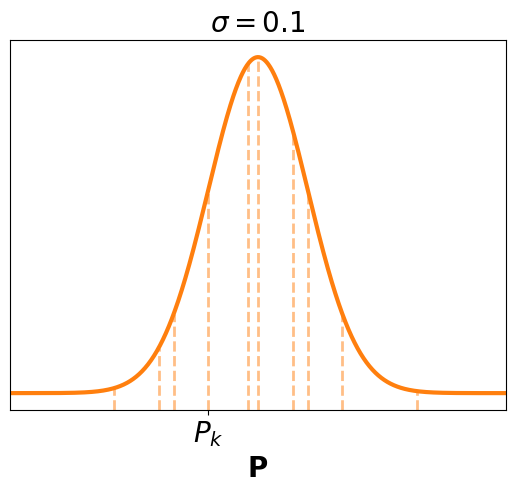

In [53]:
x = np.linspace(0, 1, 1000)

rv = ss.norm(loc=0.5, scale=0.1)


plt.plot(x, rv.pdf(x), color='C1', linewidth=3)

plt.xlim(0, 1)
plt.xticks([])
plt.yticks([])
plt.xlabel('$\mathbf{P}$', fontsize=20)


ymin, ymax = plt.ylim()
maxprob = rv.pdf(rv.mean())
diff = ymax - maxprob

def get_height(x):
    return (rv.pdf(x) - ymin) / (ymax - ymin)

p1 = 0.3
#plt.axvline(p1, ymax=get_height(p1), color='C1', linestyle='--', linewidth=2, alpha=0.5)

p1 = 0.6
#plt.axvline(p1, ymax=get_height(p1), color='C1', linestyle='--', linewidth=2, alpha=0.5)
#plt.xticks([p1], ['$P_2$'], fontsize=20)

ps = [0.3, 0.6, 0.5, 0.33, 0.67, 0.82, 0.21, 0.57, 0.48]
[plt.axvline(p, ymax=get_height(p), color='C1', linestyle='--', linewidth=2, alpha=0.5) for p in ps]

p1 = 0.4
plt.axvline(p1, ymax=get_height(p1), color='C1', linestyle='--', linewidth=2, alpha=0.5)
plt.xticks([p1], ['$P_k$'], fontsize=20)

plt.title('$\sigma = 0.1$', fontsize=20)

<>:80: SyntaxWarning: invalid escape sequence '\p'
<>:80: SyntaxWarning: invalid escape sequence '\p'
<>:98: SyntaxWarning: invalid escape sequence '\p'
<>:99: SyntaxWarning: invalid escape sequence '\m'
<>:108: SyntaxWarning: invalid escape sequence '\m'
<>:80: SyntaxWarning: invalid escape sequence '\p'
<>:80: SyntaxWarning: invalid escape sequence '\p'
<>:98: SyntaxWarning: invalid escape sequence '\p'
<>:99: SyntaxWarning: invalid escape sequence '\m'
<>:108: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1528188/140357168.py:80: SyntaxWarning: invalid escape sequence '\p'
  ax2.scatter(posterior.mean[0], posterior.mean[1], label=f'w0={pw.mean[0]:.2f}$\pm${pw.cov[0][0]:.2f}, w1={pw.mean[1]:.2f}$\pm${pw.cov[1][1]:.2f}', color='red', marker='x')
/tmp/ipykernel_1528188/140357168.py:80: SyntaxWarning: invalid escape sequence '\p'
  ax2.scatter(posterior.mean[0], posterior.mean[1], label=f'w0={pw.mean[0]:.2f}$\pm${pw.cov[0][0]:.2f}, w1={pw.mean[1]:.2f}$\pm${pw.cov[1][1]:.2f}

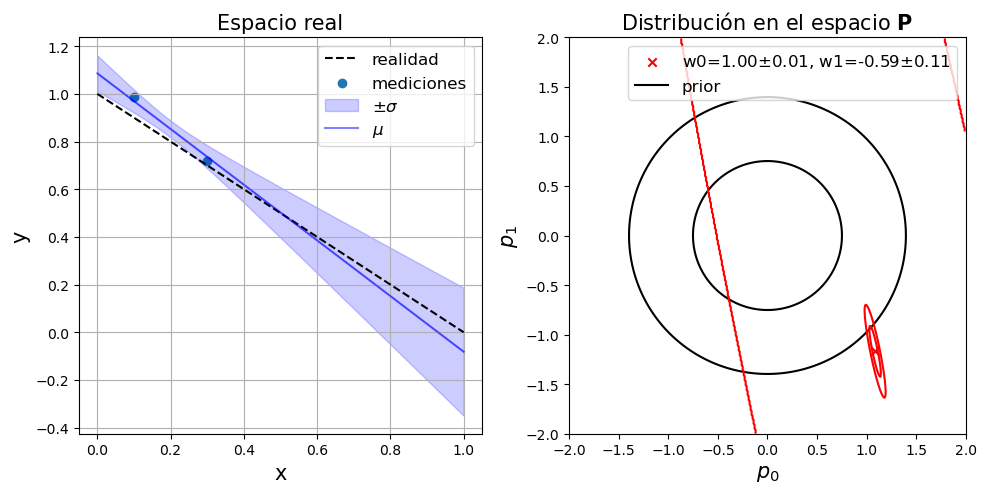

In [84]:

W_NATURE = np.array([1.0, -1.0])
SIGMA = 0.05
COVARIANCE = np.array([[1.0, 0.0], [0.0, 1.0]])

np.random.seed(0)


def model(X: np.ndarray, w: np.ndarray = W_NATURE):
    """
    Model function that computes the output based on input x and weights w.
    """
    return X.T @ w

def measure(X: np.ndarray, w: np.ndarray = W_NATURE, sigma: float = SIGMA):
    """
    Measure function that computes the output based on input x and weights w,
    adding Gaussian noise.
    """
    return model(X, w) + ss.multivariate_normal.rvs(mean=np.zeros(X.shape[1]), cov=SIGMA**2 * np.identity(X.shape[1]))

def generate_1dX(x: np.ndarray):
    """
    Generate a 1D input array for the model.
    """
    return np.hstack((np.ones_like(x), x)).T

def calc_A(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Calculate matrix A
    """
    return sigma**(-2) * X @ X.T + np.linalg.inv(cov)

def get_pw_dist(X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Get the posterior distribution of weights w given measurements y.
    """
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    m = A_inv @ X @ y / sigma**2
    return ss.multivariate_normal(mean=m, cov=A_inv)

def get_pfstar_mean(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    return xstar.T @ A_inv @ X @ y / sigma**2

def get_pfstar_var(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    return xstar.T @ A_inv @ xstar

def get_pfstar_dist(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Get the posterior distribution of weights w given measurements y and a new input xstar.
    """
    m = get_pfstar_mean(xstar, X, y, cov, sigma)
    var = get_pfstar_var(xstar, X, y, cov, sigma)
    return ss.norm(loc=m, scale=var)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
# Plot the prior distribution
w0, w1 = np.mgrid[-2:2:.01, -2:2:.01]
pos = np.dstack((w0, w1))
prior = ss.multivariate_normal(mean=np.zeros(2), cov=COVARIANCE)
ax2.contour(w0, w1, prior.pdf(pos), levels=2, colors='black', label='prior')

x = np.linspace(0, 1, 100)
X = np.array([np.ones_like(x), x])
ax1.plot(X[1], model(X), linestyle='--', label='realidad', color='black')

#n = 10
#x1s = ss.uniform(0, 1).rvs(n).reshape(-1, 1)
x1s = np.array([[0.1], [0.3]])
X = generate_1dX(x1s)
y = measure(X)
pw = get_pw_dist(X, measure(X))

posterior = get_pw_dist(X, y)
ax2.contour(w0, w1, posterior.pdf(pos), levels=2, colors='red')
ax2.scatter(posterior.mean[0], posterior.mean[1], label=f'w0={pw.mean[0]:.2f}$\pm${pw.cov[0][0]:.2f}, w1={pw.mean[1]:.2f}$\pm${pw.cov[1][1]:.2f}', color='red', marker='x')

ax1.scatter(X[1], y, label='mediciones')

xs = np.linspace(0, 1, 100)
yplus = []
yminus = []
ymean = []
for x in xs:
    x = np.array([1, x]).reshape(-1, 1)
    pfstar = get_pfstar_dist(x, X, y)
    mean, var = pfstar.mean()[0][0], pfstar.std()[0][0]
    std = np.sqrt(var)
    yplus.append(mean + std)
    yminus.append(mean - std)
    ymean.append(mean)

ax1.fill_between(xs, y1=ymean, y2=yplus, color='blue', alpha=0.2)
ax1.fill_between(xs, y1=yminus, y2=ymean, label='$\pm \sigma$', color='blue', alpha=0.2)
ax1.plot(xs, ymean, label='$\mu$', color='blue', alpha=0.5)

ax1.set_title('Espacio real', fontsize=15)
ax1.set_ylabel('y', fontsize=15)
ax1.set_xlabel('x', fontsize=15)
ax1.legend(fontsize=12)

ax2.set_ylabel('$p_1$', fontsize=15)
ax2.set_xlabel('$p_0$', fontsize=15)
ax2.set_title('Distribución en el espacio $\mathbf{P}$', fontsize=15)
ax2.set_xlim(-2, 2)
ax2.set_ylim(-2, 2)
ax2.set_aspect('equal')
ax2.plot([-100, -101], [1, 1], color='black', label='prior')
ax2.legend(fontsize=12)

ax1.grid()
plt.tight_layout()
fig.show()